# Ders 02 · Forward PINN — veri kullanmadan çözmek

**Kolay PINN · Türkişi Engineering** · Lisans + yüksek lisans · Adım 4–5

Ders 01'de kurduğumuz problemi bu kez bir sinir ağıyla, **hiç çözüm verisi kullanmadan** çözeceğiz. Ağa yalnızca
Laplace denklemini ve sınır koşullarını öğreteceğiz, sonra Ders 01'in referansıyla karşılaştıracağız.

$$
\begin{aligned}
&\frac{\partial^2\theta}{\partial\xi^2} + \frac{\partial^2\theta}{\partial\eta^2} = 0, && (\xi,\eta)\in[0,1]^2 \\
&\theta = 1, && \xi = 0,\ \xi = 1,\ \eta = 1 \\
&\frac{\partial\theta}{\partial\eta} = \mathrm{Bi}\,\theta, && \eta = 0, \qquad \mathrm{Bi} \approx 4.89
\end{aligned}
$$

**Öğrenme hedefleri**
1. Ağı ve katı kısıtı kurmak
2. PDE ve Robin artıklarını otomatik türevle yazmak
3. Adam → L-BFGS eğitim stratejisini uygulamak
4. PINN'i referansa karşı doğrulamak ve kayıp tabanını yorumlamak *(yüksek lisans derinliği)*

> Bu defterdeki eğitim kısaltılmıştır (~2–3 dk, CPU). Tam eğitim sonuçları `runs/` klasöründen yüklenir.

In [1]:
import sys, json, time, logging, warnings
from pathlib import Path
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=UserWarning)

CASE = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
ROOT = CASE.parents[1]
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(CASE))

import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.stats import qmc
from IPython.display import Image, display

from kolay_pinn.style import use_slide_style, C, INK, MUTED, cmap_thermal, cmap_error
from fdm_solver import BI_DEFAULT as Bi, analytical, solve_fdm, H_CONV, L, T_WALL, T_INF

use_slide_style(); plt.rcParams["figure.dpi"] = 110
torch.set_default_dtype(torch.float64)
torch.manual_seed(0)
ASSETS = CASE / "lecture" / "ders02" / "assets"
def goster(ad, genislik=560):
    display(Image(filename=str(ASSETS / ad), width=genislik))

print(f"torch {torch.__version__} · Bi = {Bi:.3f} · {torch.get_num_threads()} CPU iş parçacığı")

torch 2.15.0+cu132 · Bi = 4.895 · 2 CPU iş parçacığı


### Referans: Ders 01'in seri çözümü

Doğruluğu ölçmek için seri çözümü $101\times101$ ağda hazırlıyoruz:

In [2]:
N = 101
xg = np.linspace(0, 1, N)
Xg, Yg = np.meshgrid(xg, xg)
theta_ref = analytical(xg, xg, Bi)
print(f"seri çözüm, alt orta: θ = {theta_ref[0, N//2]:.4f}  ->  T = {20 + 50*theta_ref[0, N//2]:.2f} °C")

seri çözüm, alt orta: θ = 0.3308  ->  T = 36.54 °C


---
## 1 · Ağı kur

### 1.1 Çok katmanlı ağ

Girdi $(\xi, \eta)$, çıktı tek bir sayı. 4 gizli katman × 50 nöron, aktivasyon $\tanh$:

$$\mathcal{N}(\mathbf{x}) = W_5\,\sigma\big(W_4\,\sigma(\cdots\sigma(W_1\mathbf{x} + b_1)\cdots)\big) + b_5, \qquad \sigma = \tanh$$

In [3]:
class MLP(torch.nn.Module):
    def __init__(self, width=50, depth=4, act=torch.nn.Tanh):
        super().__init__()
        layers, d_in = [], 2
        for _ in range(depth):
            layers += [torch.nn.Linear(d_in, width), act()]
            d_in = width
        layers += [torch.nn.Linear(d_in, 1)]
        self.net = torch.nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, torch.nn.Linear):
                torch.nn.init.xavier_normal_(m.weight); torch.nn.init.zeros_(m.bias)
    def forward(self, X):
        return self.net(X)

model = MLP()
print(f"parametre sayısı: {sum(p.numel() for p in model.parameters()):,}")

parametre sayısı: 7,851


### 1.2 Katı kısıt

Ağın çıktısını doğrudan kullanmıyoruz. Üç Dirichlet kenarında sıfır olan bir mesafe fonksiyonuyla çarpıyoruz:

$$\hat\theta(\xi,\eta) = 1 + \underbrace{\xi\,(1-\xi)\,(1-\eta)}_{d(\xi,\eta)}\;\mathcal{N}(\xi,\eta)$$

$d = 0$ olan kenarlarda $\hat\theta = 1$, ağ ne üretirse üretsin. Alt kenar serbest; onu Robin kaybı öğretecek.

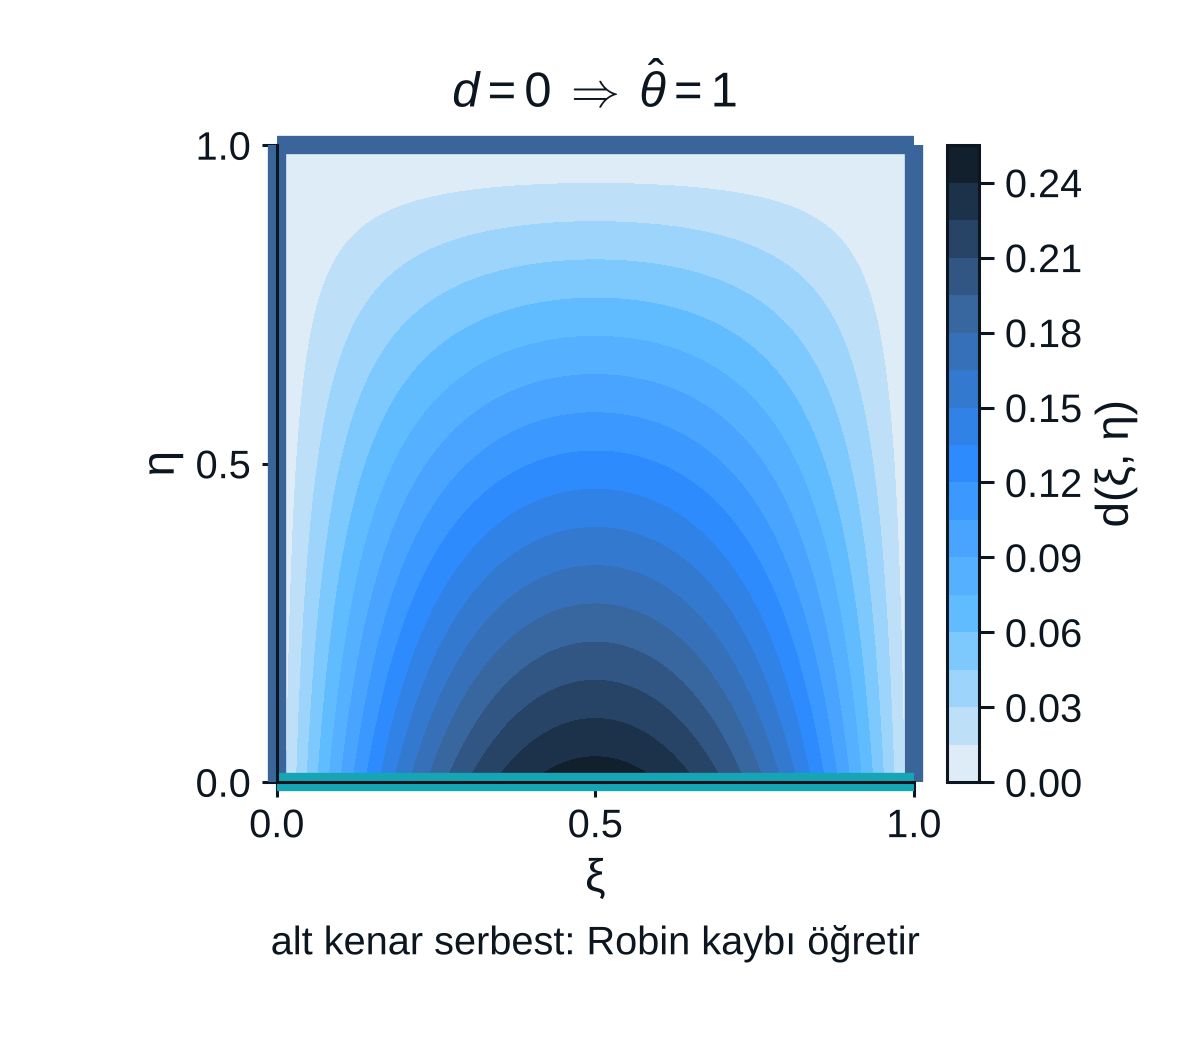

In [4]:
goster("01_distance.png", 460)

In [5]:
def theta_hat(model, X):
    xi, eta = X[:, :1], X[:, 1:2]
    return 1.0 + xi * (1.0 - xi) * (1.0 - eta) * model(X)

# Doğrulama: eğitilmemiş ağla bile üç kenarda θ̂ = 1 olmalı
s = torch.linspace(0, 1, 200)[:, None]
kenarlar = {"sol (ξ=0)": torch.cat([0*s, s], 1), "sağ (ξ=1)": torch.cat([0*s + 1, s], 1), "üst (η=1)": torch.cat([s, 0*s + 1], 1)}
with torch.no_grad():
    for ad, Xe in kenarlar.items():
        print(f"{ad:10s}  max |θ̂ − 1| = {(theta_hat(model, Xe) - 1).abs().max().item():.1e}")

sol (ξ=0)   max |θ̂ − 1| = 0.0e+00
sağ (ξ=1)   max |θ̂ − 1| = 0.0e+00
üst (η=1)   max |θ̂ − 1| = 0.0e+00


### 1.3 Aktivasyon seçimi: ReLU Laplace'ı göremez

PDE artığı ikinci türev içeriyor. ReLU parçalı doğrusal olduğu için ikinci türevi hemen her yerde sıfır:

$$\sigma(z) = \max(0, z) \;\Rightarrow\; \sigma''(z) = 0 \;\Rightarrow\; \nabla^2\mathcal{N} \equiv 0$$

Deneyle görelim: rastgele ağırlıklı bir ReLU ağının Laplace'ı her noktada sıfır çıkar.

In [6]:
def laplace(f, X):
    X = X.clone().requires_grad_(True)
    u = f(X)
    g = torch.autograd.grad(u, X, torch.ones_like(u), create_graph=True)[0]
    uxx = torch.autograd.grad(g[:, 0:1], X, torch.ones_like(u), create_graph=True)[0][:, 0]
    uyy = torch.autograd.grad(g[:, 1:2], X, torch.ones_like(u), create_graph=True)[0][:, 1]
    return (uxx + uyy).detach()

Xr = torch.rand(1000, 2)
relu_net, tanh_net = MLP(act=torch.nn.ReLU), MLP()
print(f"ReLU ağı: max |∇²N| = {laplace(relu_net, Xr).abs().max().item():.1e}   <- her yerde sıfır")
print(f"tanh ağı: max |∇²N| = {laplace(tanh_net, Xr).abs().max().item():.1e}")

ReLU ağı: max |∇²N| = 0.0e+00   <- her yerde sıfır
tanh ağı: max |∇²N| = 7.2e-01


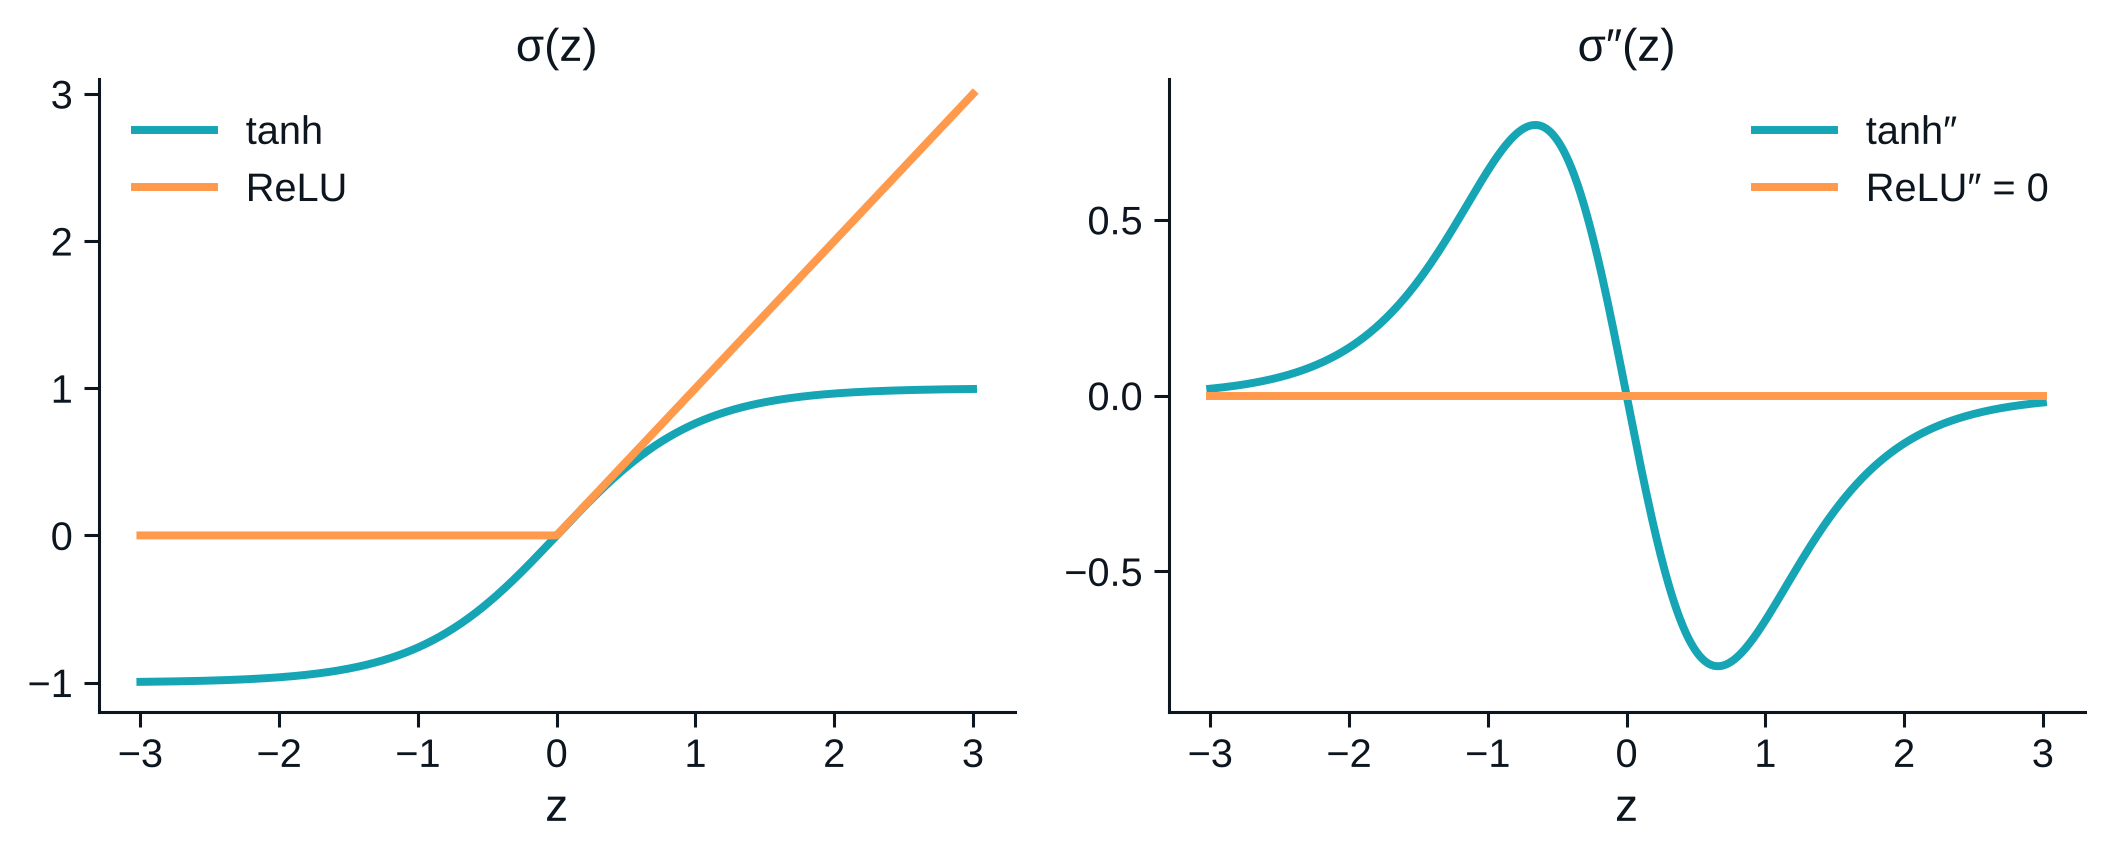

In [7]:
goster("02_activations.png", 760)

---
## 2 · Kayıp ve eğitim

### 2.1 Otomatik türev

Türevleri ağın hesap grafiğinden **kesin** alıyoruz. `create_graph=True`, türevin de türevini almamızı sağlar:

$$\nabla^2\hat\theta = \frac{\partial}{\partial\xi}\!\left(\frac{\partial\hat\theta}{\partial\xi}\right) + \frac{\partial}{\partial\eta}\!\left(\frac{\partial\hat\theta}{\partial\eta}\right)$$

Bir noktada otomatik türevi merkezi sonlu farkla karşılaştıralım:

In [8]:
def grad(u, X):
    return torch.autograd.grad(u, X, torch.ones_like(u), create_graph=True)[0]

p = torch.tensor([[0.3, 0.4]])
lap_ad = laplace(lambda X: theta_hat(model, X), p).item()

h = 1e-3
f = lambda a, b: theta_hat(model, torch.tensor([[a, b]])).item()
lap_fd = (f(0.3 + h, 0.4) + f(0.3 - h, 0.4) + f(0.3, 0.4 + h) + f(0.3, 0.4 - h) - 4 * f(0.3, 0.4)) / h**2
print(f"otomatik türev: ∇²θ̂ = {lap_ad:+.8f}")
print(f"sonlu fark    : ∇²θ̂ = {lap_fd:+.8f}   (fark {abs(lap_ad - lap_fd):.1e}, O(h²) kesme hatası)")

otomatik türev: ∇²θ̂ = -0.04962694
sonlu fark    : ∇²θ̂ = -0.04962693   (fark 1.0e-08, O(h²) kesme hatası)


### 2.2 Kolokasyon noktaları

Denklemi zorlayacağımız noktalar: iç bölgede Sobol dizisi (rastgeleden daha düzgün) ve alt kenarda ayrı bir dizi.

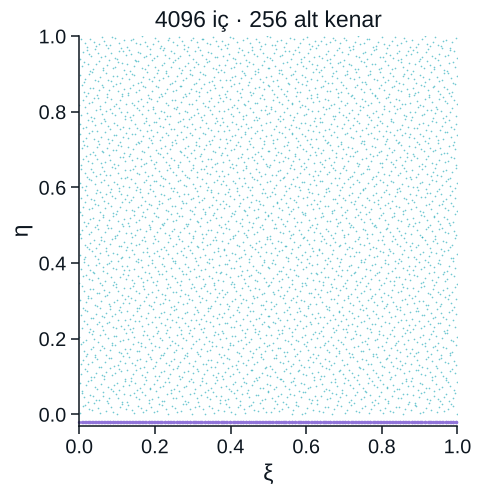

In [9]:
n_int, n_bot = 4096, 256
X_int = torch.tensor(qmc.Sobol(2, scramble=True, seed=0).random(n_int), requires_grad=True)
xb = qmc.Sobol(1, scramble=True, seed=1).random(n_bot)[:, 0]
X_bot = torch.tensor(np.column_stack([xb, np.zeros_like(xb)]), requires_grad=True)

fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.scatter(*X_int.detach().numpy().T, s=1.2, color=C["plan"], alpha=0.6, linewidths=0)
ax.scatter(xb, np.full_like(xb, -0.02), s=5, color=C["lila"], linewidths=0, clip_on=False)
ax.set(aspect="equal", xlim=(0, 1), ylim=(-0.03, 1), xlabel="ξ", ylabel="η", title=f"{n_int} iç · {n_bot} alt kenar")
plt.show()

### 2.3 Kayıp

$$\mathcal{L}(\mathbf{w}) = \frac{1}{N_r}\sum_{k=1}^{N_r} \big(\nabla^2\hat\theta(\mathbf{x}_k)\big)^2
+ \frac{\lambda}{N_b}\sum_{m=1}^{N_b} \Big(\frac{\partial\hat\theta}{\partial\eta} - \mathrm{Bi}\,\hat\theta\Big)^2_{(\xi_m,\,0)},
\qquad \lambda = 1$$

Dirichlet terimi yok: katı kısıt onu yapı gereği sağladı.

In [10]:
def kayip(model, lam=1.0):
    th = theta_hat(model, X_int)
    g = grad(th, X_int)
    r_pde = grad(g[:, :1], X_int)[:, :1] + grad(g[:, 1:2], X_int)[:, 1:2]
    tb = theta_hat(model, X_bot)
    r_rob = grad(tb, X_bot)[:, 1:2] - Bi * tb
    l_pde, l_rob = (r_pde**2).mean(), (r_rob**2).mean()
    return l_pde + lam * l_rob, l_pde, l_rob

L0, lp, lr = kayip(model)
print(f"eğitimden önce: L = {L0.item():.3e}   (PDE {lp.item():.2e}, Robin {lr.item():.2e})")

eğitimden önce: L = 2.332e+01   (PDE 2.04e-02, Robin 2.33e+01)


### 2.4 Eğitim: Adam → L-BFGS

Adam gürültülü adımlarla kötü başlangıçtan kurtulur; iyi bir havzaya gelince L-BFGS eğriliği kullanarak kaybı
mertebelerce indirir. Burada kısaltılmış bir eğitim yapıyoruz (tam koşu: 6000 Adam + 2000 L-BFGS).

In [11]:
ADAM, LBFGS = 1500, 400
gecmis = []
t0 = time.perf_counter()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
for it in range(ADAM):
    opt.zero_grad(); Lt, lp, lr = kayip(model); Lt.backward(); opt.step()
    if it % 25 == 0: gecmis.append((it, Lt.item(), lp.item(), lr.item()))
    if it % 500 == 0: print(f"Adam {it:5d}  L = {Lt.item():.3e}")

lb = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=LBFGS, history_size=50, line_search_fn="strong_wolfe",
                       tolerance_grad=1e-11, tolerance_change=1e-14)
k = [ADAM]
def closure():
    lb.zero_grad(); Lt, lp, lr = kayip(model); Lt.backward()
    if k[0] % 10 == 0: gecmis.append((k[0], Lt.item(), lp.item(), lr.item()))
    k[0] += 1
    return Lt
lb.step(closure)
Lt, lp, lr = kayip(model)
print(f"L-BFGS sonu: L = {Lt.item():.3e}  (PDE {lp.item():.2e}, Robin {lr.item():.2e}) · süre {time.perf_counter() - t0:.0f} s")

Adam     0  L = 2.332e+01


Adam   500  L = 3.021e+00


Adam  1000  L = 1.201e+00


L-BFGS sonu: L = 2.045e-01  (PDE 1.56e-02, Robin 1.89e-01) · süre 114 s


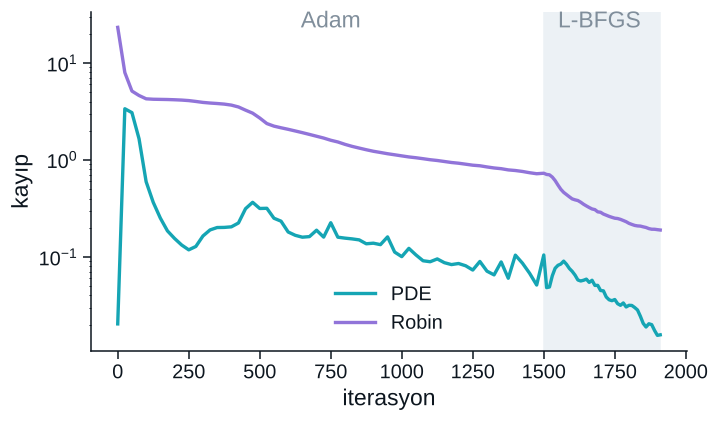

In [12]:
g = np.array(gecmis)
fig, ax = plt.subplots(figsize=(7, 4))
ax.axvspan(ADAM, g[:, 0].max(), color=C["krom"], zorder=0)
ax.semilogy(g[:, 0], g[:, 2], color=C["plan"], label="PDE")
ax.semilogy(g[:, 0], g[:, 3], color=C["lila"], label="Robin")
ax.set(xlabel="iterasyon", ylabel="kayıp"); ax.legend()
ax.text(ADAM / 2, g[:, 3].max(), "Adam", ha="center", color=MUTED); ax.text(ADAM + 50, g[:, 3].max(), "L-BFGS", color=MUTED)
plt.show()

---
## 3 · Doğrula

### 3.1 Alan ve hata

bağıl L2 hata = 1.97e-03
maksimum |hata| = 3.03e-02  @ (ξ, η) = (0.02, 0.00)
alt orta: PINN 36.54 °C · seri 36.54 °C


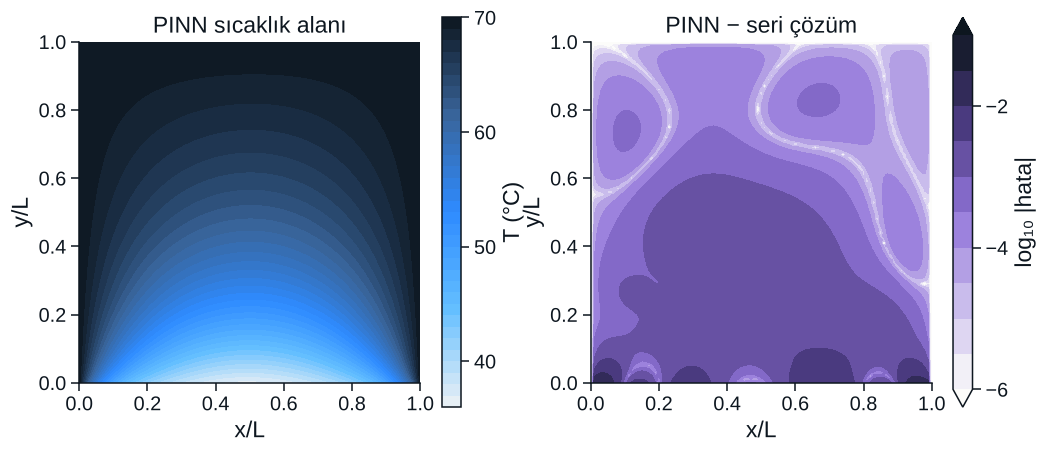

In [13]:
P = torch.tensor(np.column_stack([Xg.ravel(), Yg.ravel()]))
with torch.no_grad():
    theta_pinn = theta_hat(model, P).numpy().reshape(N, N)
hata = theta_pinn - theta_ref
print(f"bağıl L2 hata = {np.linalg.norm(hata) / np.linalg.norm(theta_ref):.2e}")
print(f"maksimum |hata| = {np.abs(hata).max():.2e}  @ (ξ, η) = ({xg[np.abs(hata).argmax() % N]:.2f}, {xg[np.abs(hata).argmax() // N]:.2f})")
print(f"alt orta: PINN {20 + 50*theta_pinn[0, N//2]:.2f} °C · seri {20 + 50*theta_ref[0, N//2]:.2f} °C")

fig, axs = plt.subplots(1, 2, figsize=(11, 4.6))
cf = axs[0].contourf(Xg, Yg, 20 + 50 * theta_pinn, levels=np.linspace(36, 70, 35), cmap=cmap_thermal)
fig.colorbar(cf, ax=axs[0], label="T (°C)", ticks=[40, 50, 60, 70])
ce = axs[1].contourf(Xg, Yg, np.log10(np.maximum(np.abs(hata), 1e-8)), levels=np.arange(-6, -0.99, 0.5), cmap=cmap_error, extend="both")
fig.colorbar(ce, ax=axs[1], label="log₁₀ |hata|", ticks=[-6, -4, -2])
for a, t in zip(axs, ["PINN sıcaklık alanı", "PINN − seri çözüm"]):
    a.set(aspect="equal", xlabel="x/L", ylabel="y/L", title=t)
plt.show()

### 3.2 Mühendislik çıktısı: $Q'$

$$Q' = \bar h\,L\,(T_w - T_\infty)\int_0^1 \hat\theta(\xi, 0)\,d\xi$$

In [14]:
xf = np.linspace(0, 1, 4001)
with torch.no_grad():
    tb = theta_hat(model, torch.tensor(np.column_stack([xf, 0 * xf]))).numpy()[:, 0]
I_p = np.trapezoid(tb, xf)
I_e = np.trapezoid(analytical(xf, np.array([0.0]), Bi)[0], xf)
Q = lambda I: H_CONV * L * (T_WALL - T_INF) * I
print(f"Q' PINN = {Q(I_p):,.0f} W/m · seri = {Q(I_e):,.0f} W/m · fark %{100 * abs(I_p - I_e) / I_e:.2f}")

Q' PINN = 5,582 W/m · seri = 5,531 W/m · fark %0.93


### 3.3 Kayıp tabanı: kalan kayıp nereden geliyor? *(yüksek lisans)*

Eğitim sonunda kayıp sıfıra inmiyor ve neredeyse tamamı Robin teriminden geliyor. Alt kenar boyunca Robin artığına bakalım:

kenarın %2'lik köşe şeridinin Robin kaybındaki payı: %88.6
köşede |r| = 4.89  (Bi = 4.89)


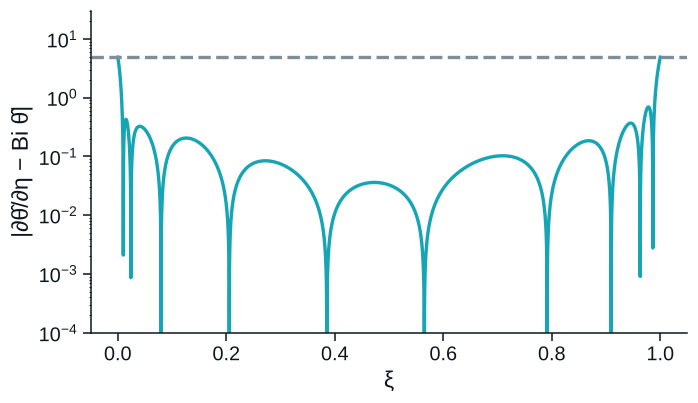

In [15]:
xs = np.linspace(0, 1, 20001)
Xb2 = torch.tensor(np.column_stack([xs, 0 * xs]), requires_grad=True)
tb2 = theta_hat(model, Xb2)
r = (grad(tb2, Xb2)[:, 1:2] - Bi * tb2).detach().numpy()[:, 0]
kose = (xs < 0.01) | (xs > 0.99)
print(f"kenarın %2'lik köşe şeridinin Robin kaybındaki payı: %{100 * (r[kose]**2).sum() / (r**2).sum():.1f}")
print(f"köşede |r| = {abs(r[0]):.2f}  (Bi = {Bi:.2f})")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.semilogy(xs, np.abs(r) + 1e-12, color=C["plan"])
ax.axhline(Bi, color=MUTED, ls="--"); ax.set(xlabel="ξ", ylabel="|∂θ̂/∂η − Bi θ̂|", ylim=(1e-4, 30))
plt.show()

Köşede iki koşul çelişiyor. Yan duvarda $\theta \equiv 1$ olduğu için duvar boyunca $\partial\theta/\partial\eta = 0$;
Robin ise köşede bu türevin $\mathrm{Bi}$ olmasını istiyor:

$$\underbrace{\left.\frac{\partial\theta}{\partial\eta}\right|_{\xi=0} = 0}_{\text{yan duvar}}
\qquad\text{ama}\qquad
\underbrace{\frac{\partial\theta}{\partial\eta} = \mathrm{Bi}\,\theta = \mathrm{Bi}}_{\text{Robin, köşede}}$$

Hiçbir düzgün fonksiyon ikisini birden sağlayamaz. **Kaybın mutlak değeri doğruluk ölçüsü değildir**; doğruluğu referansla ölçeriz.

---
## 4 · Tam eğitim koşuları ve köşe deneyi

`pinn_forward.py` ile üç tam koşu yapıldı (6000 Adam + ≤ 2000 L-BFGS):

1. **düzgün** — Sobol iç noktalar, düzgün Robin noktaları
2. **köşe sıklaştırma** — Ders 01'in FDM sezgisi: hata köşedeyse oraya nokta koy (alt köşelere 1024 iç + 128 Robin noktası)
3. **köşe dışlama** — tersi: köşeden $\delta = 0.02$ mesafedeki Robin noktalarını kayıptan çıkar

In [16]:
TAGS = ("uniform", "corner", "skip")
R = {t: json.loads((CASE / "runs" / t / "metrics.json").read_text()) for t in TAGS}
print(f"{'':22s}{'düzgün':>12s}{'sıklaştırma':>13s}{'dışlama':>11s}")
for k, lab, f in [("final_loss", "son kayıp", "{:.1e}"), ("rel_L2", "bağıl L2", "{:.2e}"), ("rel_L2_interior", "bağıl L2 (iç bölge)", "{:.2e}"),
                  ("max_err", "maksimum hata", "{:.2e}"), ("T_mid_bottom_C", "alt orta T (°C)", "{:.2f}"),
                  ("Q_rel_err", "Q' bağıl hata", "{:.2%}"), ("t_total_s", "süre (s)", "{:.0f}")]:
    print(f"{lab:22s}{f.format(R['uniform'][k]):>12s}{f.format(R['corner'][k]):>13s}{f.format(R['skip'][k]):>11s}")

                            düzgün  sıklaştırma    dışlama
son kayıp                  9.9e-02      1.6e+00    4.3e-04
bağıl L2                  9.54e-04     4.61e-03   1.08e-03
bağıl L2 (iç bölge)       4.92e-04     4.54e-03   5.20e-04
maksimum hata             2.80e-02     2.04e-02   3.23e-02
alt orta T (°C)              36.51        36.51      36.55
Q' bağıl hata                0.24%        1.20%      0.49%
süre (s)                       492          607        467


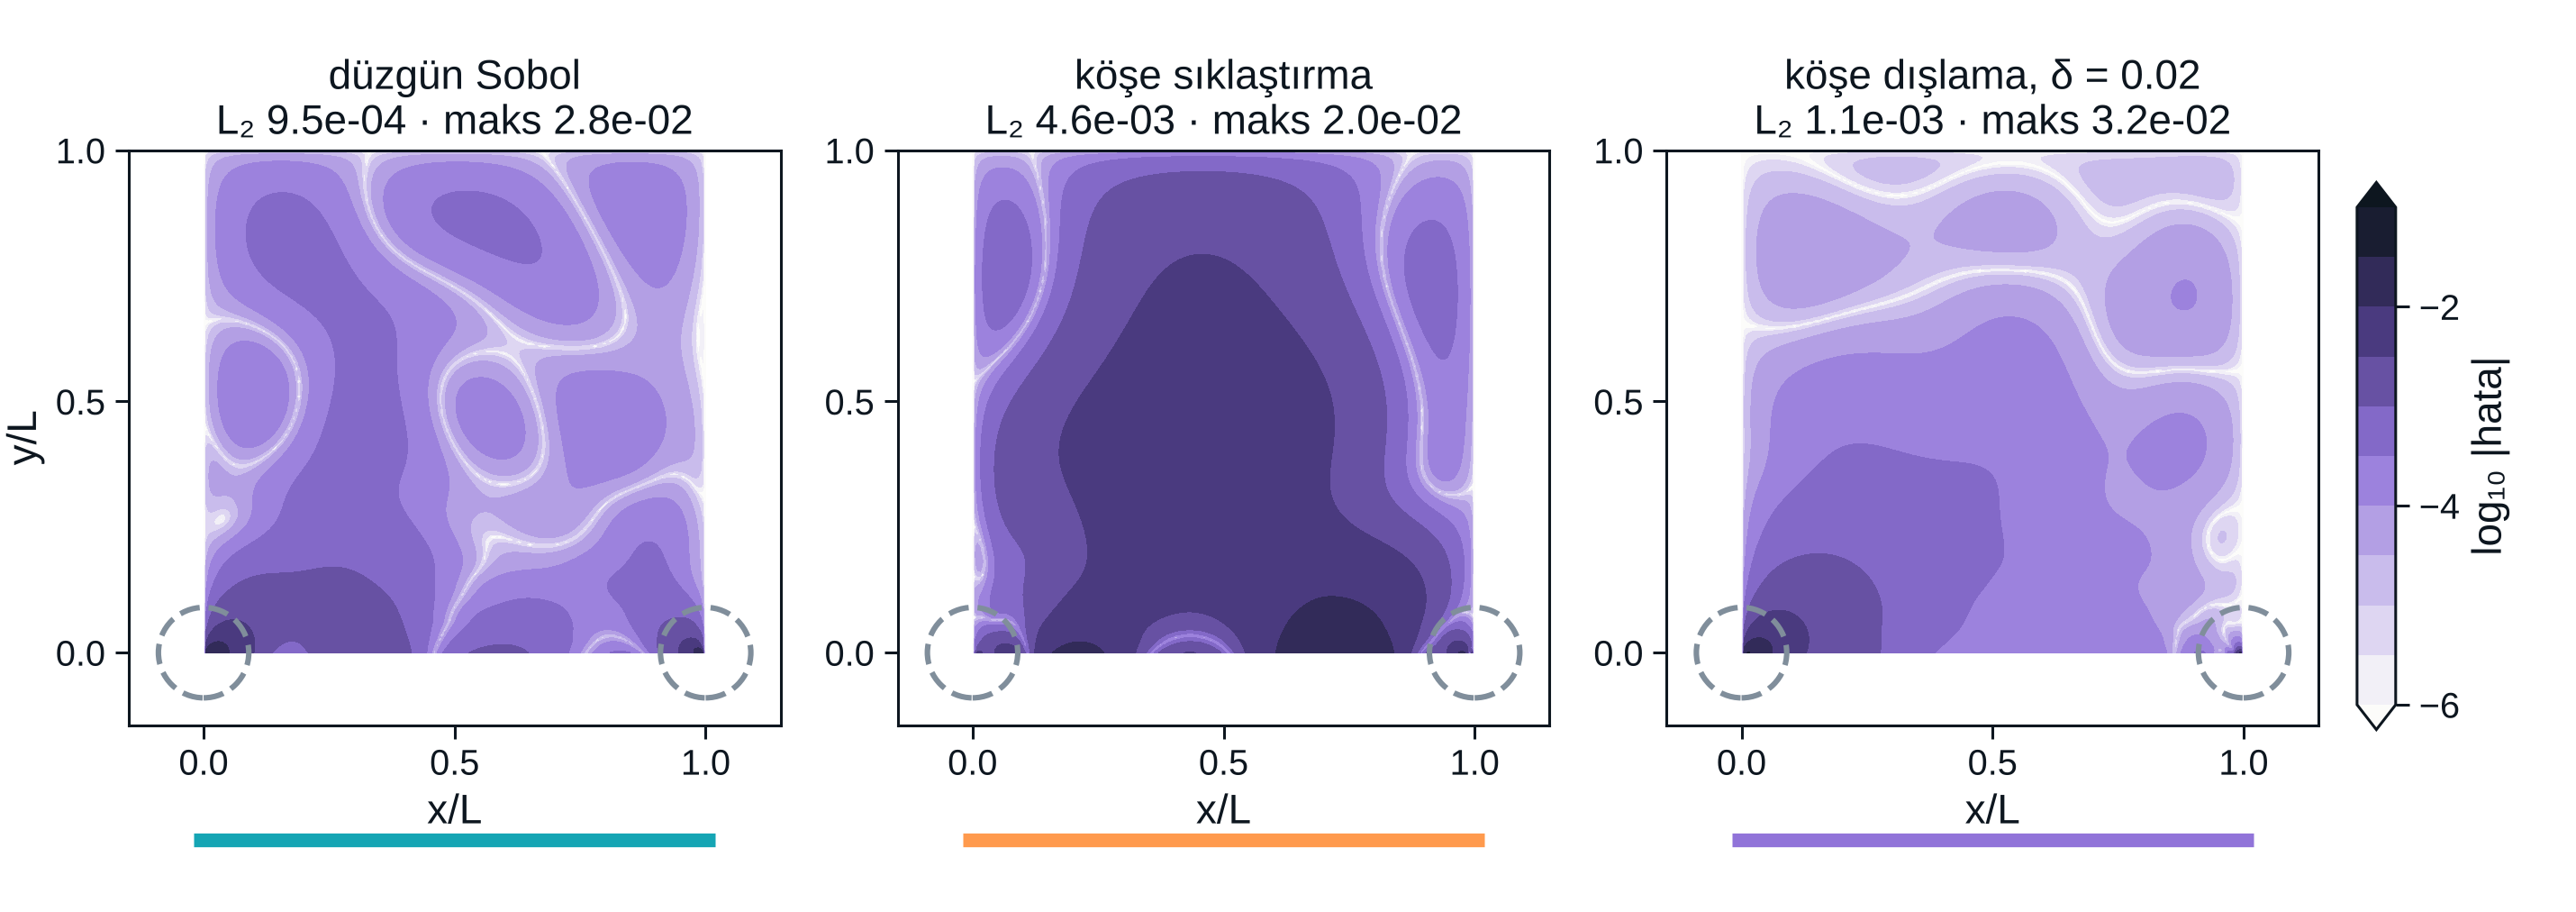

In [17]:
goster("06_error_maps.png", 900)

**Köşe sıklaştırma ters tepti.** FDM'de her düğüm kendi denklemini sağlar; köşeye düğüm eklemek yalnız orayı iyileştirir.
PINN'de ise tek bir düzgün fonksiyon tüm noktalardaki artıkların ortalamasını küçültür. Köşedeki Robin artığı hiçbir düzgün
fonksiyonla sıfırlanamadığı için, o noktaları çoğaltmak kaybın ağırlığını imkânsız bir hedefe kaydırır ve alanın geri kalanı bozulur.

**Köşe dışlama kaybı iki yüz kattan fazla düşürdü ama hatayı değiştirmedi.** Kayıp tabanı köşe çelişkisinden geliyordu ve çözümün
geri kalanına zarar vermiyordu. Kaybın küçülmesi çözümün iyileştiği anlamına gelmez; doğruluğu referansla ölçeriz.

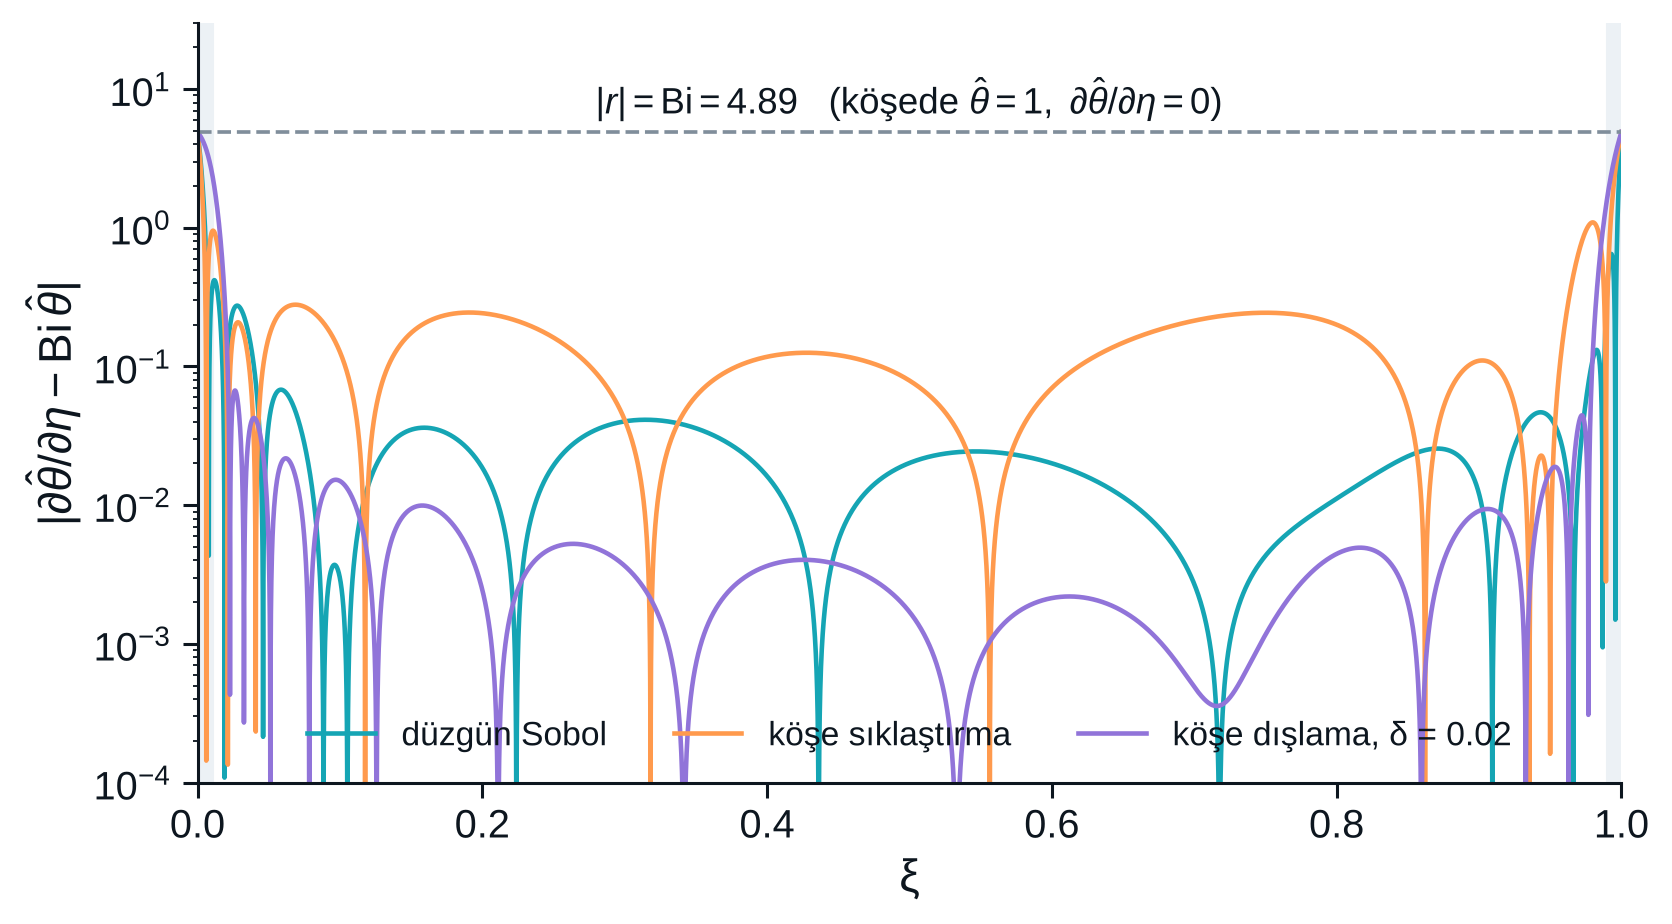

In [18]:
goster("08_robin_residual.png", 680)

### PINN ve FDM

| | FDM ($N = 101$) | PINN (4 × 50, tanh) |
|---|---|---|
| Bağıl $L_2$ hata | $1.1\times10^{-4}$ | en iyi koşu: yukarıdaki tablo |
| Süre (2 CPU) | < 1 s | birkaç dakika |
| Ağ / mesh | gerekli | gerekmez |
| Çözüm | düğüm değerleri | sürekli, türevlenebilir |
| Ölçüm verisi ekleme | zor | kayba bir terim (Adım 6) |
| Bilinmeyen parametre | dış optimizasyon | aynı eğitimde (Adım 7) |

Bu problemde FDM hem daha doğru hem daha hızlı. PINN'in değeri veri ve bilinmeyenler devreye girince ortaya çıkıyor.

---
## Özet

- Fizik kayıp olur: Laplace ve Robin artıkları; katı kısıt Dirichlet'i yapıya gömer, $\tanh$ ikinci türevi taşır.
- Başarıyı kayıp değil referans ölçer; kayıp tabanını köşe çelişkisi belirler.
- FDM sezgisi PINN'e doğrudan taşınmaz: köşeye nokta eklemek hatayı artırır.
- Köşeyi dışlamak kaybı iki yüz kattan fazla düşürür ama hatayı değiştirmez: **kayıp ≠ doğruluk**.
- Sıradaki ders: seyrek ve gürültülü ölçümleri kayba eklemek (hibrit PINN):

$$\mathcal{L} = \mathcal{L}_{\mathrm{PDE}} + \lambda\,\mathcal{L}_{\mathrm{Robin}} + \mu\,\frac{1}{N_d}\sum_{i=1}^{N_d}\big(\hat\theta(\mathbf{x}_i) - \theta_i^{\text{ölçüm}}\big)^2$$

## Alıştırmalar

**Lisans:** (1) genişlik 20 / 50 / 100 ile L₂ hata ve süre tablosu · (2) λ = 0.1, 1, 10 · (3) $Q'$'yü PINN'den hesaplayın.

**Yüksek lisans:** (1) yumuşak kısıt ile katı kısıtı karşılaştırın · (2) ReLU ile eğitip kaybın neden sıfıra gittiğini gösterin ·
(3) Köşe tekilliğini çözüme analitik olarak ekleyin; L₂ ve $Q'$ değişir mi?

In [19]:
# Alıştırma alanı — Lisans 1: daha dar bir ağla kısa eğitim
torch.manual_seed(0)
dar = MLP(width=20)
opt = torch.optim.Adam(dar.parameters(), lr=1e-3)
for it in range(500):
    opt.zero_grad(); Lt, _, _ = kayip(dar); Lt.backward(); opt.step()
with torch.no_grad():
    th20 = theta_hat(dar, P).numpy().reshape(N, N)
print(f"genişlik 20, 500 Adam adımı: bağıl L2 = {np.linalg.norm(th20 - theta_ref) / np.linalg.norm(theta_ref):.2e}")

genişlik 20, 500 Adam adımı: bağıl L2 = 2.72e-02
